# Exploratory Data Analysis: weather

* **Data:** `/Users/ani/Projects/16_weather_prediction/data/raw/open_meteo_daily_2024-01-01_2026-10-01.csv`
* **Mode:** targeted, with the target below
* **Target column:** `temperature_2m_max` (continuous)
* **Date column:** `date`
* **ID columns:** `city`
* **Shared spec:** `/Users/ani/Projects/16_weather_prediction/ml_spec.yaml`. The summary checks the data against its framing, and the last cell writes the results to its `eda` section.

The first rows of the data are shown once, right after loading. The report sections below show summary
statistics only, and values of identifier, free text, and personal data columns are never shown in them.
Every section can be rerun on its own after you change the data.

## Setup

In [1]:
import importlib.util
import os
import sys

# This notebook was built for: 16_weather_prediction (.venv, Python 3.11.8) (/Users/ani/Projects/16_weather_prediction/.venv/bin/python)
# If a package is missing below, the notebook is running on a different Python. In VS Code or Jupyter,
# choose "Select Kernel" and pick 16_weather_prediction (.venv, Python 3.11.8), then restart the kernel and run all cells.
print("Kernel Python:", sys.executable)
missing = [m for m in ("pandas", "numpy", "matplotlib", "seaborn") if importlib.util.find_spec(m) is None]
if missing:
    raise ModuleNotFoundError(
        f"This kernel ({sys.executable}) is missing: {', '.join(missing)}. "
        "Select the kernel for 16_weather_prediction (.venv, Python 3.11.8) (/Users/ani/Projects/16_weather_prediction/.venv/bin/python), or install them into this kernel with "
        f"%pip install {' '.join(missing)}"
    )

import pandas as pd

# The EDA engine lives in the ml-eda-report skill folder.
sys.path.insert(0, r"/Users/ani/.claude/skills/ml-eda-report/scripts")
from eda_core import EDAReport

# Shared project spec. The EDA reads the framing from it and writes its results back in the last cell.
from ml_common import load as load_spec
SPEC_PATH = r"/Users/ani/Projects/16_weather_prediction/ml_spec.yaml"
spec = load_spec(SPEC_PATH) if os.path.exists(SPEC_PATH) else None

Kernel Python: /Users/ani/Projects/16_weather_prediction/.venv/bin/python


In [2]:
df = pd.read_csv(r"/Users/ani/Projects/16_weather_prediction/data/raw/open_meteo_daily_2024-01-01_2026-10-01.csv", low_memory=False)
print(f"Loaded {len(df):,} rows and {df.shape[1]:,} columns")

Loaded 50,250 rows and 23 columns


In [3]:
df.head()

,city,country,latitude,longitude,grid_latitude,grid_longitude,elevation,timezone,date,temperature_2m_max,...,apparent_temperature_min,precipitation_sum,rain_sum,snowfall_sum,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,shortwave_radiation_sum,sunshine_duration,weather_code
0,London,United Kingdom,51.5074,-0.1278,51.493847,-0.163025,16.0,Europe/London,2024-01-01,10.9,...,1.0,10.5,10.5,0.0,30.6,51.8,225,2.39,6276.83,61
1,London,United Kingdom,51.5074,-0.1278,51.493847,-0.163025,16.0,Europe/London,2024-01-02,12.9,...,2.5,7.4,7.4,0.0,52.3,90.4,230,0.56,0.00,61
2,London,United Kingdom,51.5074,-0.1278,51.493847,-0.163025,16.0,Europe/London,2024-01-03,10.4,...,2.7,2.3,2.3,0.0,25.9,45.7,245,2.71,27210.10,61
3,London,United Kingdom,51.5074,-0.1278,51.493847,-0.163025,16.0,Europe/London,2024-01-04,8.3,...,1.5,30.3,30.3,0.0,27.4,46.8,240,2.30,10052.49,65
4,London,United Kingdom,51.5074,-0.1278,51.493847,-0.163025,16.0,Europe/London,2024-01-05,7.1,...,-1.0,2.1,2.1,0.0,33.7,57.2,309,2.04,3184.94,63


## Full report

The next cell runs every check once. Each section below then displays its own results.

In [4]:
eda = EDAReport(
    df,
    target='temperature_2m_max',
    target_type='continuous',
    corr_threshold=0.9,
    cramers_threshold=0.8,
    date_col='date',
    id_cols=['city'],
    name='weather',
    sample_rows=200000,
    max_plots=24,
    log_scale=False,
    mode='targeted',
    spec=spec,
).run()
print(f"{len(eda.issues)} issues flagged and {eda.figure_count} plots created")

23 issues flagged and 6 plots created


## 1. Overview

Size, sampling, column roles, duplicates, the grain of the data, and type problems.

In [5]:
eda.show("overview", header=False)

The data has **50,250 rows** and **23 columns**, and uses about **10.7 MB** of memory. Every statistic and plot uses all rows.

**Columns by role:** 18 numeric, 2 categorical, 1 identifier, 1 dates stored as text, 1 target. Roles are the skill's best guess at how each column should be treated. Identifier, free text, and possible personal data columns are excluded from value level output.

* **Duplicate rows:** 0 rows (0.00%) are exact copies of another row.
* **Grain:** one row per combination of `date` and `city`. No single column is unique, but these pairs are: `date` + `city`.
* `city` repeats on 50,250 rows. 50,250 of those rows share the ID but differ in at least one other column, which often points to a join problem upstream.

**Type problems:** `date` (dates stored as text). Each one is also in the Flags column of the profile tables.

## 2. Column Profiles

One row per column. Numeric columns first, then categorical columns, then dates and other columns. Together these tables cover everything df.info() and df.describe(include="all") show, plus a Flags column that lists the issues found for each column.

In [6]:
eda.show("profiles", header=False)

**Numeric columns**

Sorted by Missing %, then Outlier %, lowest first. P1 to P99 are percentiles, and P25, Median, and P75 are the quartiles from df.describe(). Outlier % uses the 1.5 × IQR rule. An absolute skew above 2 means a strongly skewed distribution.

Column,Dtype,Count,Missing %,Unique,Mean,Std,Min,P1,P5,P25,Median,P75,P95,P99,Max,Skew,Zero %,Negative %,Outlier %,Flags
temperature_2m_max,float64,"50,250",0,638,22.80,9.94,-25.50,-3.90,4.10,16.90,23.80,30.20,36.80,42.50,47.60,-0.583,0.0418,2.16,1.22,target
latitude,float64,"50,250",0,50,22.09,27.96,-36.85,-36.85,-33.92,4.71,30.64,41.01,59.33,64.15,64.15,-0.751,0,22,0,highly correlated with grid_latitude
longitude,float64,"50,250",0,50,3.04,82.99,-149.9,-149.9,-122.3,-74.07,12.95,55.27,139.7,174.8,174.8,0.0777,0,44,0,highly correlated with grid_longitude
grid_latitude,float64,"50,250",0,48,22.09,27.97,-36.87,-36.87,-33.99,4.75,30.65,41.02,59.37,64.08,64.08,-0.751,0,22,0,highly correlated with latitude
grid_longitude,float64,"50,250",0,50,3.04,82.99,-149.9,-149.9,-122.3,-74.10,12.97,55.30,139.7,174.8,174.8,0.0779,0,44,0,highly correlated with longitude
snowfall_sum,float64,"50,250",0,153,0.0604,0.59,0,0,0,0,0,0,0,1.75,22.96,17.25,96.62,0,0,highly skewed
wind_direction_10m_dominant,int64,"50,250",0,361,177.1,103.2,0,3,15,88,182,259,342,357,360,-0.0102,0.137,0,0,
shortwave_radiation_sum,float64,"50,250",0,"3,260",17.21,7.42,0.03,0.81,3.31,11.92,18.32,22.93,27.97,30.36,33.99,-0.387,0,0,0,
weather_code,int64,"50,250",0,13,30.53,27.95,0,0,0,3,51,55,65,73,75,0.0327,8.30,0,0,highly correlated with precipitation_sum
apparent_temperature_min,float64,"50,250",0,696,13.64,11.86,-42.90,-16.20,-6.60,6,13.40,23.20,31.20,33.80,42,-0.309,0.143,12.61,0.474,highly correlated with 3 columns


**Categorical columns**

Sorted by Missing %, then Unique %, lowest first. The most common value is hidden when it appears fewer than 5 times. Rare categories each cover under 1% of non missing rows.

Column,Dtype,Count,Missing %,Unique,Unique %,Most common value,Most common count,Most common share %,Rare categories (<1%),Rows in rare categories %,Flags
country,str,"50,250",0,36,0.07,United States,"9,045",18,0,0,
timezone,str,"50,250",0,43,0.09,Asia/Kolkata,"3,015",6,0,0,


**Date columns**

Placeholder dates are 1900-01-01, 1970-01-01, and 9999-12-31.

Column,Stored as,Count,Missing %,Unique,Earliest,Latest,Span (days),Future dates %,Before 1900 %,Placeholder dates %,Flags
date,text,"50,250",0,"1,005",2024-01-01,2026-10-01,"1,004",0,0,0,dates stored as text


**Identifier, personal data, and other columns (values not shown)**

Column,Role,Dtype,Count,Missing %,Unique,Flags
city,identifier,str,"50,250",0,50,repeated IDs


## 3. Missing Values

Which columns have missing values, disguised missing values, which columns are missing together, and whether the missingness looks structural.

In [7]:
eda.show("missing", header=False)

No column has missing values according to df.isna().

## 4. Distributions

Histograms for numeric columns, top values for categorical columns, and rows over time.

Each panel shows a box plot above a histogram, and the orange line is the median. The profile table has the exact statistics. Every column is plotted on its original scale with all of its values. Pass log_scale=True to plot strongly skewed columns on a log axis instead.

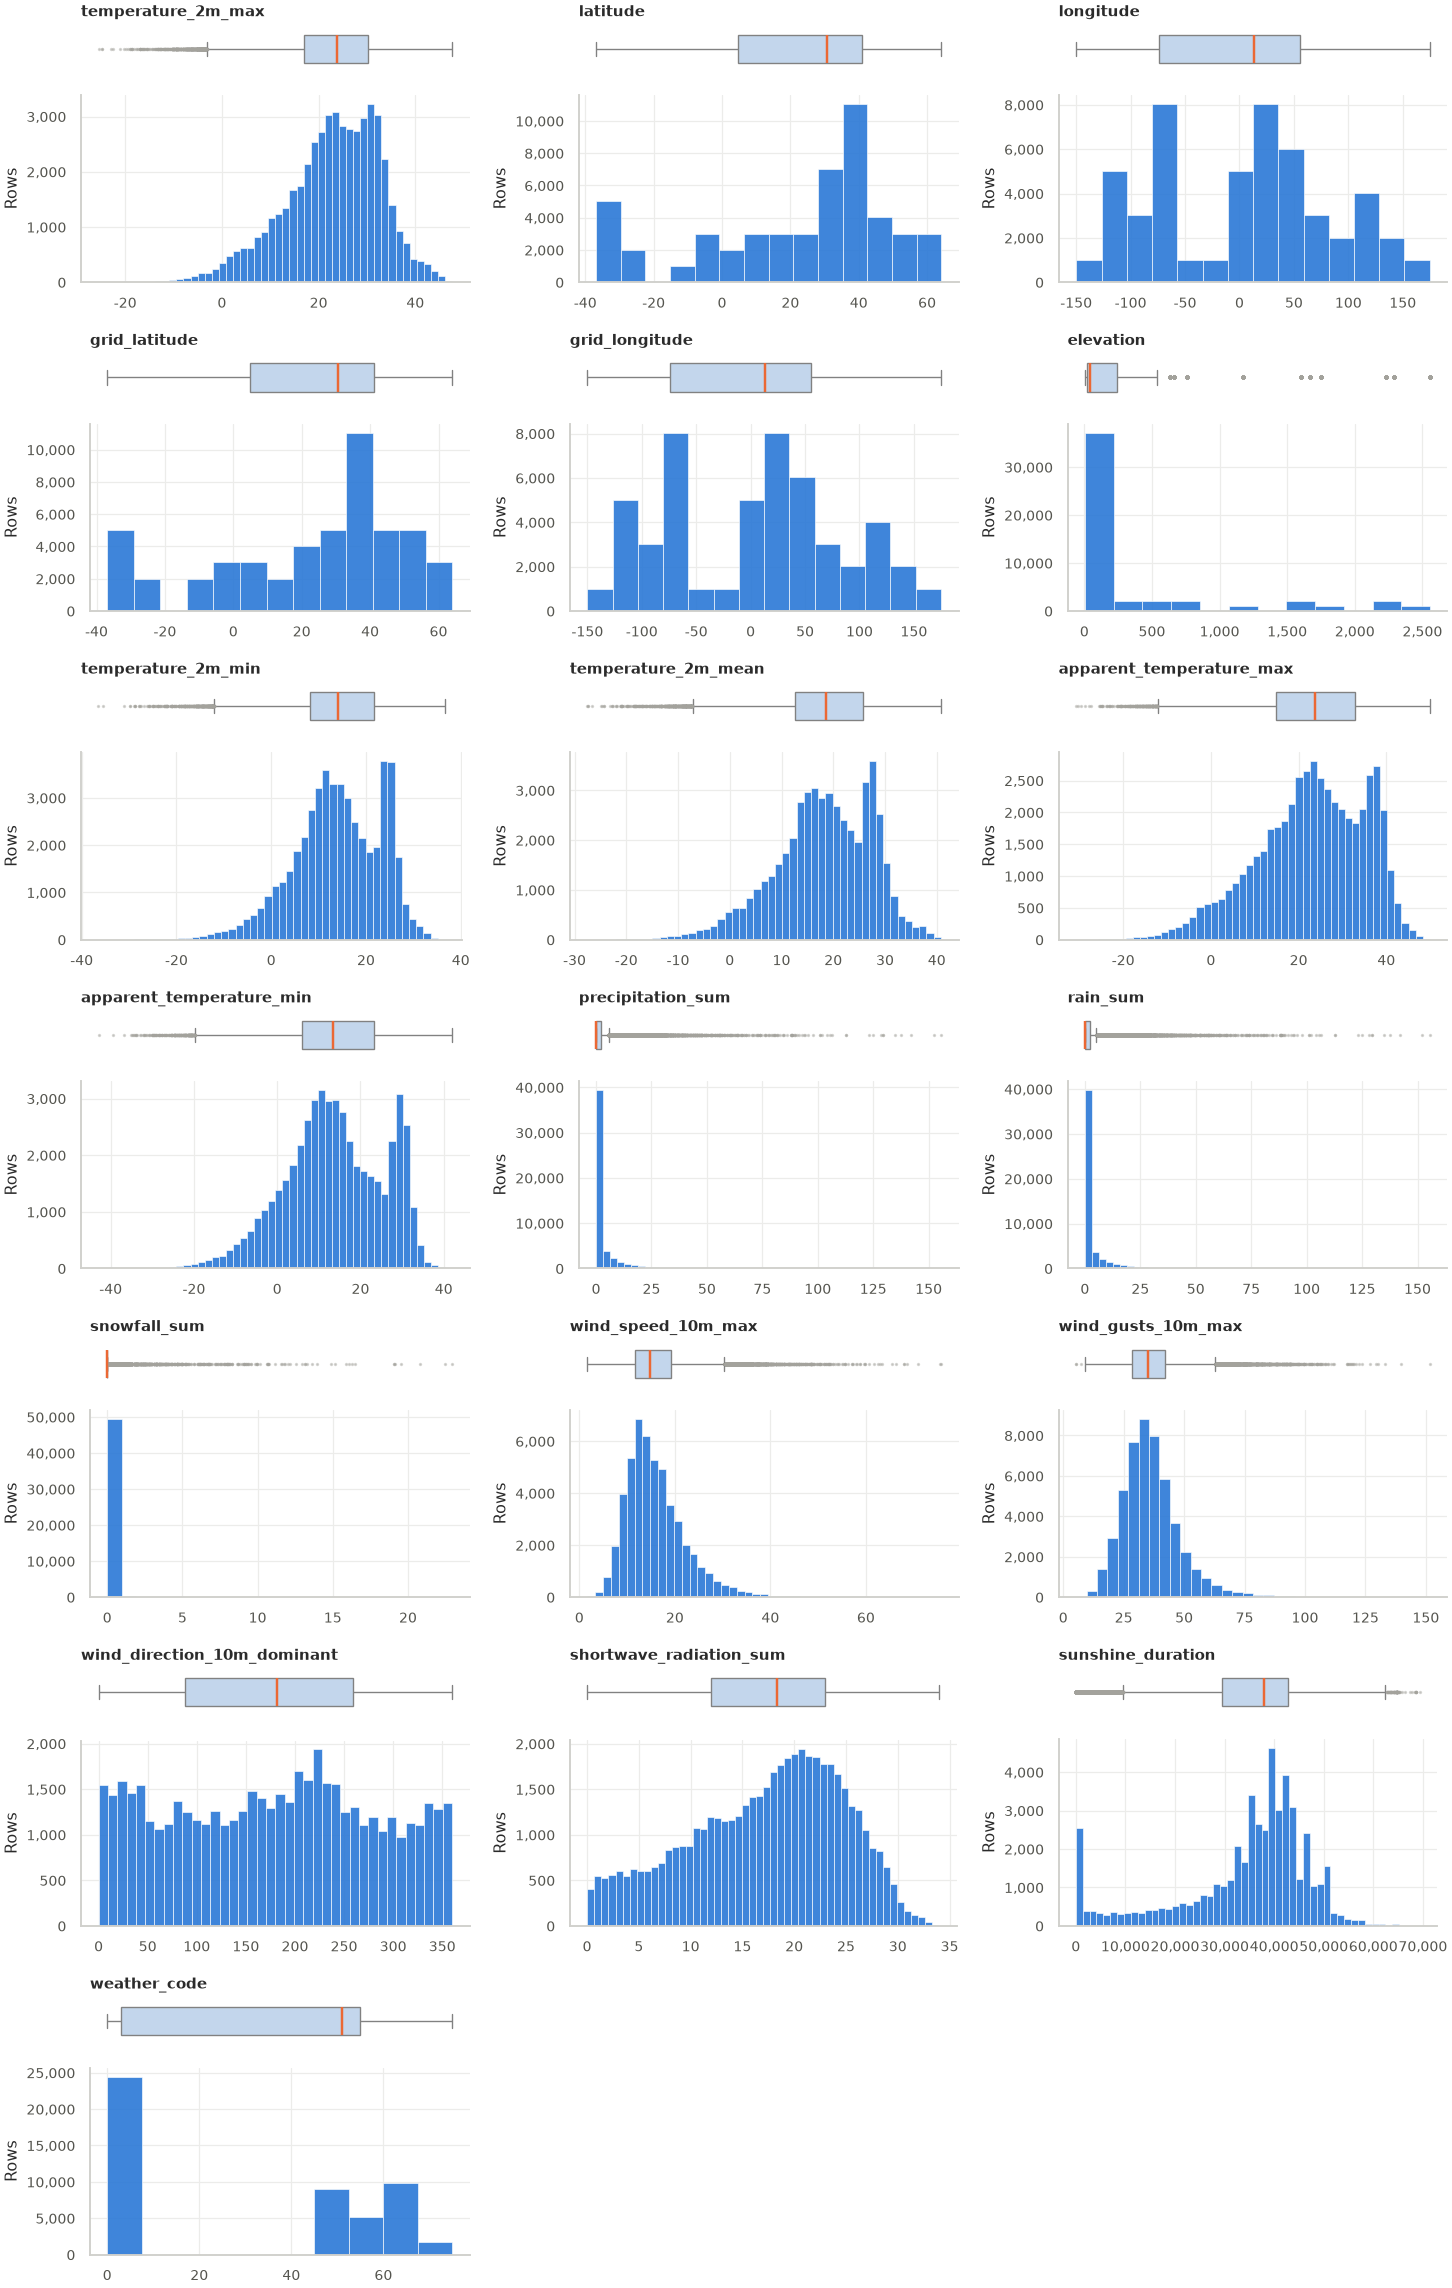

Each panel shows the 10 most common values as a share of rows. Grey bars group the remaining values (Other) and missing values. Values seen fewer than 5 times are always in Other.

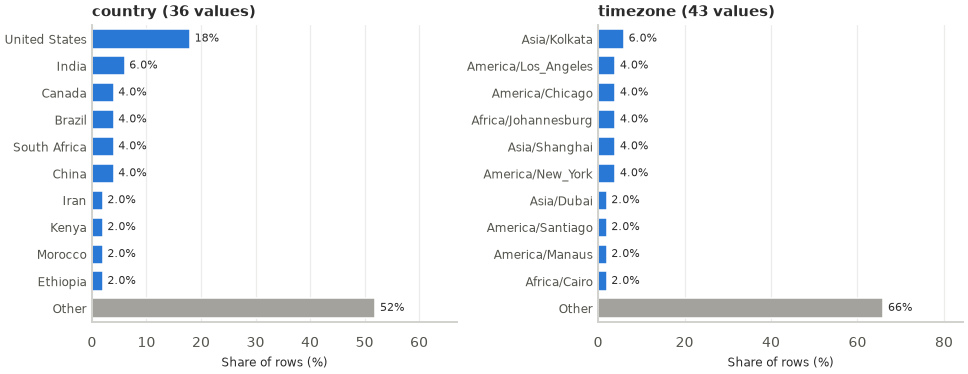

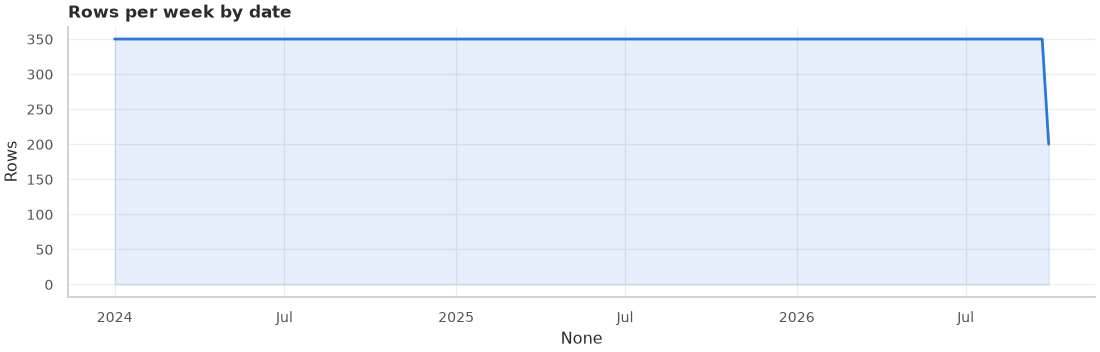

* Row counts are grouped by week of `date`, over 144 periods.

In [8]:
# top_n: how many numeric and how many categorical columns to plot. None plots up to max_plots columns.
# With a target, the top columns are the ones most associated with it, so try top_n=10.
# log_scale: True plots strongly skewed numeric columns on a log axis, False on their original scale.
eda.show("distributions", header=False, top_n=None, log_scale=False)

## 5. Relationships Between Columns

Correlation between numeric columns, association between categorical columns, and date ordering.

**Highly correlated numeric pairs (|Spearman| ≥ 0.9)**

10 pairs found.

Column A,Column B,Spearman
longitude,grid_longitude,1
latitude,grid_latitude,1
temperature_2m_min,apparent_temperature_min,0.99
temperature_2m_mean,apparent_temperature_max,0.98
precipitation_sum,rain_sum,0.979
temperature_2m_min,temperature_2m_mean,0.975
temperature_2m_mean,apparent_temperature_min,0.962
apparent_temperature_max,apparent_temperature_min,0.946
temperature_2m_min,apparent_temperature_max,0.945
precipitation_sum,weather_code,0.922


**Strongly associated categorical pairs (Cramér's V ≥ 0.8)**

1 pairs found.

Column A,Column B,Cramér's V
country,timezone,1


Left: Spearman correlation between numeric columns (from minus 1 to 1). Right: Cramér's V between categorical columns with 2 to 50 values (from 0 to 1).

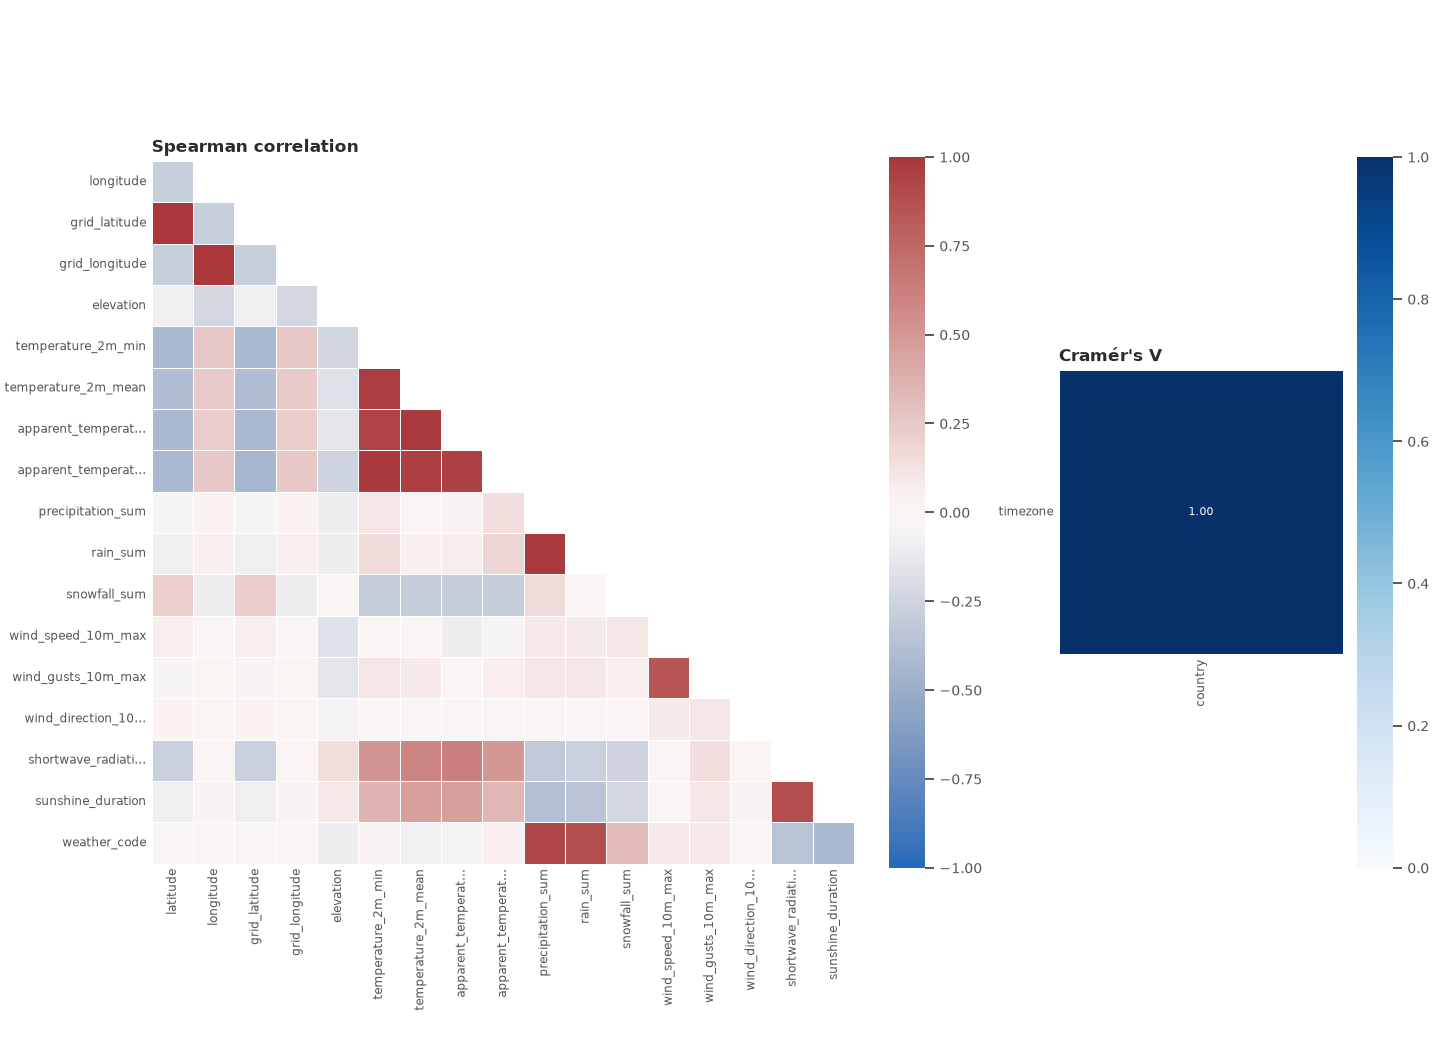

In [9]:
# Change the thresholds to list more or fewer pairs. The heatmaps are not recomputed.
eda.show("relationships", header=False, corr_threshold=0.9, cramers_threshold=0.8)

## 6. Target Analysis

Target balance, feature relationships with the target, and leakage warnings.

`temperature_2m_max` is treated as a **continuous** target (regression), as you specified. It has 638 unique values, and 0.00% of target values are missing.

Its distribution is in the numeric profile table and the distribution plots.

**Feature relationships with the target (strongest first)**

Spearman is used for numeric features with a numeric or binary target, Eta (correlation ratio) for numeric and categorical pairs, and Cramér's V for two categorical columns. All run from 0 to 1 in strength, and Spearman can be negative. Mutual information captures non linear relationships.

Feature,Type,Measure,Association,Mutual information
apparent_temperature_max,numeric,Spearman,0.98,1.85
temperature_2m_mean,numeric,Spearman,0.976,1.69
temperature_2m_min,numeric,Spearman,0.914,1.03
apparent_temperature_min,numeric,Spearman,0.901,0.974
shortwave_radiation_sum,numeric,Spearman,0.664,0.389
timezone,categorical,Eta,0.657,0.578
country,categorical,Eta,0.604,0.52
sunshine_duration,numeric,Spearman,0.511,0.234
grid_latitude,numeric,Spearman,-0.382,0.604
latitude,numeric,Spearman,-0.382,0.609


**Possible leakage**

These are warnings, not proof. Confirm that each feature is known at prediction time.

Feature,Reasons
temperature_2m_mean,Association with the target is 0.976.
apparent_temperature_max,Association with the target is 0.980.


The 9 features most related to the target, in order of strength. Each title shows the feature's association with the target (the measure is named) and its mutual information (MI). Numeric features are 2D histograms against the target (darker means more rows, 0.5% tails trimmed). Categorical features show the mean target for their 10 most common values.

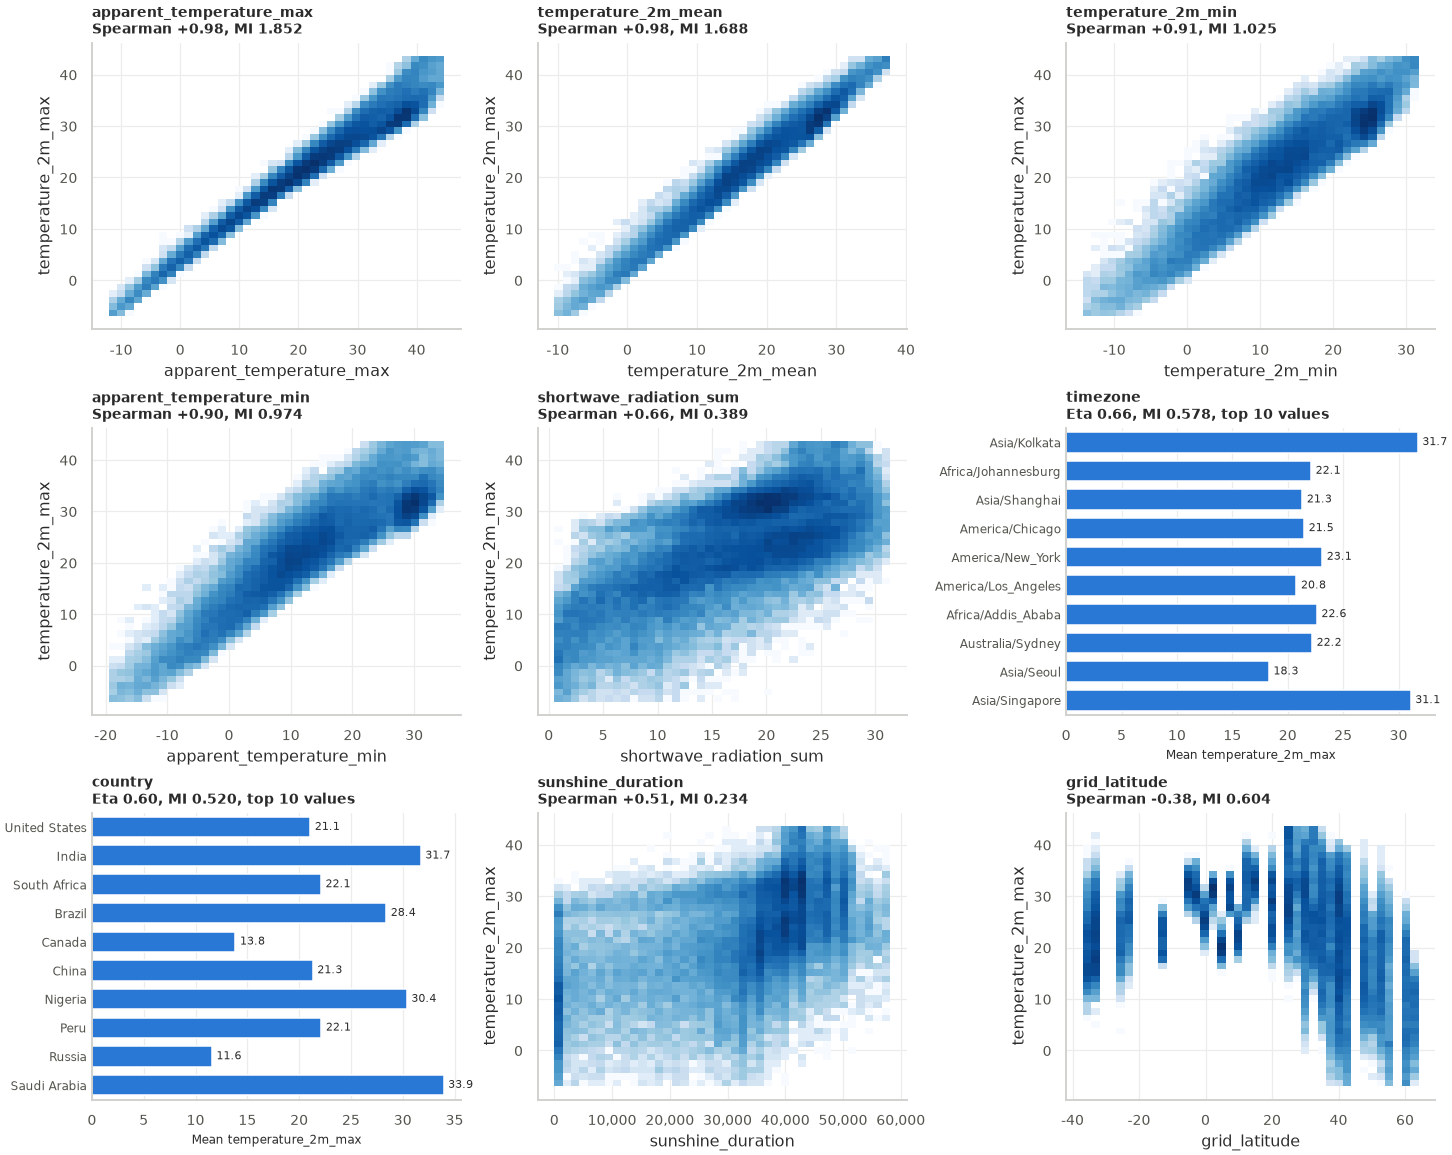

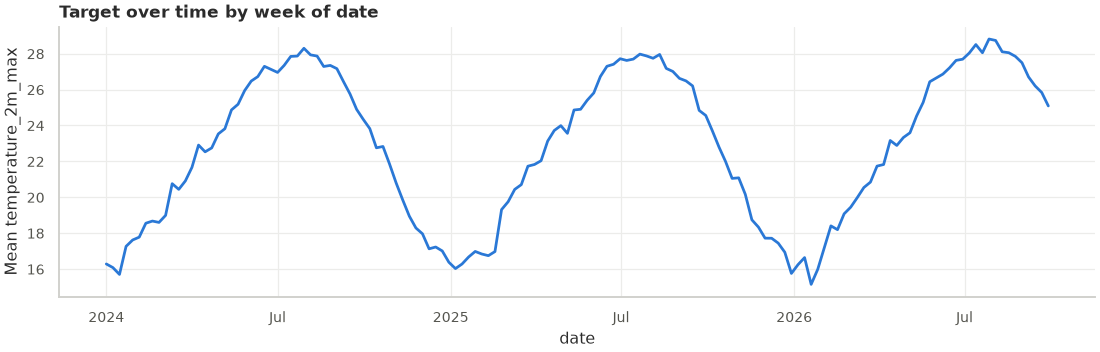

In [10]:
# top_n: number of features to list and plot. min_association: smallest absolute association with the target.
# min_mutual_info: smallest mutual information. All three can be None. Nothing is recomputed.
eda.show("target", header=False, top_n=None, min_association=None, min_mutual_info=None)

## 7. Data Quality Summary and Next Steps

Checks against the ML framing when a spec is given, issues grouped by type and ranked by severity, checks that found nothing, and next steps.

In [11]:
eda.show("summary", header=False)

**Checks against the ML framing in ml_spec.yaml**

Fail means the data contradicts the framing. Check means a person should confirm something.

Check,Result,Detail
Target column exists,Pass,`temperature_2m_max` is in the data.
Target type matches the task type,Pass,"`temperature_2m_max` is continuous, as forecasting needs."
Rows per `city`,Check,"50 distinct values over 50,250 rows, about 1005.0 rows each. Split by `city` or by time so the same entity is not in both train and test."
Grain matches the unit of prediction,Pass,"Framing: One city on one target date (the city's next local day, seen from a request). Every row has a unique `city` + `date`, which matches."
Prediction time column exists,Pass,`date` runs from 2024-01-01 to 2026-10-01.
Leakage suspects handled,Check,"Not yet excluded: `temperature_2m_mean`, `apparent_temperature_max`."


The checks found **7 kinds of issue**: 2 High, 1 Medium, and 4 Low. High issues can change model results or conclusions and should be resolved first. The Flags column in the profile tables shows the same findings for each column.

**Issues by type**

Severity,Area,Finding,Columns,Suggested action
High,Target,Possible leakage,"2: `temperature_2m_mean`, `apparent_temperature_max`","Confirm the feature is available at prediction time, and drop it if it is not."
High,Keys and duplicates,ID column is not unique,"1: `city` (50,250 rows differ)","Check whether the data should have one row per ID, and look for a many to many join."
Medium,Data types,Dates stored as text,1: `date`,Convert with pd.to_datetime.
Low,Relationships,Highly correlated numeric pairs (|Spearman| ≥ 0.9),"10: `longitude` and `grid_longitude` (1.00), `latitude` and `grid_latitude` (1.00), `temperature_2m_min` and `apparent_temperature_min` (0.99), `temperature_2m_mean` and `apparent_temperature_max` (0.98), `precipitation_sum` and `rain_sum` (0.98), `temperature_2m_min` and `temperature_2m_mean` (0.97), `temperature_2m_mean` and `apparent_temperature_min` (0.96), `apparent_temperature_max` and `apparent_temperature_min` (0.95), `temperature_2m_min` and `apparent_temperature_max` (0.94), `precipitation_sum` and `weather_code` (0.92)","Consider keeping only one of each pair for linear models, and check whether one is derived from the other."
Low,Numeric columns,Highly skewed (absolute skew above 2),"4: `elevation` (2.1), `precipitation_sum` (5.8), `rain_sum` (5.9), `snowfall_sum` (17.2)",Consider a log or rank transform for linear models.
Low,Numeric columns,Many outliers (over 5% of rows by the IQR rule),"4: `elevation` (20.0%), `precipitation_sum` (15.1%), `rain_sum` (15.6%), `sunshine_duration` (9.3%)",Check whether extreme values are real before capping them.
Low,Relationships,Strongly associated categorical pairs (Cramér's V ≥ 0.8),1: `country` and `timezone` (1.00),"One of each pair may be redundant, or one may be a grouping of the other."


**Checks that found nothing:** no constant or near constant columns; no missing values; no disguised missing values; no values that differ only by case, spaces, or punctuation; the data matches the ML framing on every hard check.

**Suggested next steps**

* Fix the column types listed above.
* Resolve duplicate rows or keys before splitting or aggregating the data.
* Confirm that the features flagged for possible leakage are known at prediction time.
* Decide on transforms or capping for skewed numeric columns if you plan to use linear models.
* Use a time based split for validation, since the data has a date column and a target.
* This report does not change the data. Apply fixes in your own pipeline and rerun the report to confirm them.

## Update the shared spec

Writes the results above to the `eda` section of the spec. Rerun this cell after changing the data or the settings.

In [12]:
path, created = eda.write_spec(SPEC_PATH, source=r"/Users/ani/Projects/16_weather_prediction/data/raw/open_meteo_daily_2024-01-01_2026-10-01.csv", report=r"/Users/ani/Projects/16_weather_prediction/notebooks/04_eda_open_meteo_daily_2024_01_01_2026_10_01.ipynb")
print(("Created" if created else "Updated"), path)

Updated /Users/ani/Projects/16_weather_prediction/ml_spec.yaml


## Save a markdown copy (optional)

Uncomment to also write the report as markdown with PNG plots.

In [13]:
# eda.to_markdown("docs")  # writes docs/eda_<name>.md and docs/eda_plots/<name>/